# Age-Metallicity Relation (AMR) Analysis 

Here the Age-Metallicity Relation (AMR) for the cleaned catalogues of globular clusters found in Vandenberg (2013) & Krause (2016) will be outlined.

In [49]:
# Import libraries.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("globular_clusters_cleaned.csv")
fehlabel = "[Fe/H] (dex)"
agelabel = "Age (Gyr)"
data.head()

,FeH,Age,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,...,r_h,mu_V,rho_0,lg_tc,lg_th,Mstar,rh,C5,Age_Krause,FeH_Krause
0,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,...,3.17,14.38,4.88,7.84,9.55,6.46,7.10,0.92,12.80,-0.76
1,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,...,2.23,20.05,1.78,8.99,9.32,0.46,9.80,0.05,12.20,-1.32
2,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,...,0.82,14.80,4.74,7.76,8.93,2.50,3.50,0.72,10.00,-1.26
3,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,...,0.68,17.73,2.99,8.59,9.12,3.41,5.50,0.62,10.24,-1.08
4,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,...,0.51,14.25,5.09,7.43,8.82,5.51,3.05,1.81,7.64,-1.13


In [50]:
# Check data is loaded correctly
data.head()
data.columns

Index(['FeH', 'Age', 'Age_err', 'Method', 'Figs', 'Range', 'HBtype', 'R_G',
       'M_V', 'v_e0', 'log_sigma_0', 'Cluster_ID', 'RA', 'DEC', 'L', 'B',
       'R_Sun', 'R_gc', 'X', 'Y', 'Z', 'v_r', 'v_r_e', 'v_LSR', 'sig_v',
       'sig_v_e', 'c', 'r_c', 'r_h', 'mu_V', 'rho_0', 'lg_tc', 'lg_th',
       'Mstar', 'rh', 'C5', 'Age_Krause', 'FeH_Krause'],
      dtype='str')

In [51]:
# Check for missing values in the age and metallicity columns of both datasets
data[["Cluster_ID", "FeH", "Age", "Age_err", "FeH_Krause", "Age_Krause"]].isna().sum()

Cluster_ID    0
FeH           0
Age           0
Age_err       0
FeH_Krause    3
Age_Krause    3
dtype: int64

Original data labelling guide for VandenBerg et al. (2013).
- Cluster_ID: Identifier of the globular cluster
- FeH: Metallicity, [Fe/H]
- Age: Absolute age (Gyr)
- Age_err: Uncertainty in the age (Gyr). This is only the isochrone-fitting error (approximately ±0.25 Gyr); VandenBerg et al. note that distance and chemical abundance uncertainties add a further factor of approximately ±1.5-2 Gyr.


Original data labelling guide for Krause et al. (2016).
- Age_Krause: Age (Gyr), compiled from data sets.
- FeH_Krause: Metallicity, [Fe/H] 


In [52]:
# Confirm the total number of clusters in each dataset.
print(data["Cluster_ID"].nunique())                    # VandenBerg
print(data["Age_Krause"].notna().sum())                # Krause

# Clusters in VandenBerg that are missing from Krause
print(data.loc[data["Age_Krause"].isna(), "Cluster_ID"])

55
52
7     NGC4147
52       Arp2
54    Terzan8
Name: Cluster_ID, dtype: str


## Fitting the Age-Metallicity Relation

A line of best fit, Age = a [Fe/H] + b, is calculated and depicted for the two graph. The fit is repeated, each time leaving out clusters more than 3σ from the line, so that extreme clusters do not pull the fit. The VandenBerg fit is weighted by 1/Age_err (note these errors are fitting errors only, so the weights reflect relative, not total, uncertainty). Krause possesses no given age uncertainty hence the plot displayed possesses an unweighted fit.

Clusters whose residual from the final line is greater than 2σ are taken as outliers.

In [ ]:
# Implement astronomical figures from cleaned catalogue for globular clusters (FeH,Age, Age_err)                          
FeH, Age, Age_err = data["FeH"], data["Age"], data["Age_err"]
# Create a new DataFrame for Krause data, dropping rows with missing values in Age_Krause and FeH_Krause
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"]).copy()

# Define a function to fit the Age-Metallicity Relation (AMR) using weighted linear regression with iterative sigma clipping.

def fit_amr(x, y, yerr=None, clip=3, niter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if yerr is None else 1 / np.asarray(yerr)
    keep = np.ones_like(x, dtype=bool)
    for _ in range(niter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

# Fit the AMR for both datasets and store the results in the DataFrame.

aV, bV, sigmaV, residV = fit_amr(FeH, Age, Age_err)
data["residV"] = residV
print(f"VandenBerg: Age = {aV:.2f} [Fe/H] + {bV:.2f}, scatter = {sigmaV:.2f} Gyr")

aK, bK, sigmaK, residK = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause["residK"] = residK
print(f"Krause: Age = {aK:.2f} [Fe/H] + {bK:.2f}, scatter = {sigmaK:.2f} Gyr")

VandenBerg: Age = -0.92 [Fe/H] + 10.54, scatter = 0.48 Gyr
Krause: Age = -0.54 [Fe/H] + 11.75, scatter = 1.02 Gyr


In [ ]:
# Identify outliers based on residuals exceeding 2 times the standard deviation for both datasets.
out1 = data[np.abs(data["residV"]) > 2 * sigmaV]
out2 = krause[np.abs(krause["residK"]) > 2 * sigmaK]
print(out1[["Cluster_ID", "FeH", "Age", "residV"]])
print(out2[["Cluster_ID", "FeH_Krause", "Age_Krause", "residK"]])

   Cluster_ID   FeH    Age    residV
2      NGC362 -1.30  10.75 -0.993203
3     NGC1261 -1.27  10.75 -0.965497
23    NGC6218 -1.33  13.00  1.229091
28    NGC6362 -1.07  12.50  0.969208
53      Pal12 -0.81   9.00 -2.290674
   Cluster_ID  FeH_Krause  Age_Krause    residK
2      NGC362       -1.26       10.00 -2.430529
3     NGC1261       -1.08       10.24 -2.092629
4     NGC1851       -1.13        7.64 -4.719824
32    NGC6535       -1.51       10.50 -2.066502
53      Pal12       -0.81        8.60 -3.585779


## Plot 1: Plotting the Outlier Significance of the AMR (Vandenberg vs Krause) coloured by Kinematic Outlier Significance (v_LSR)

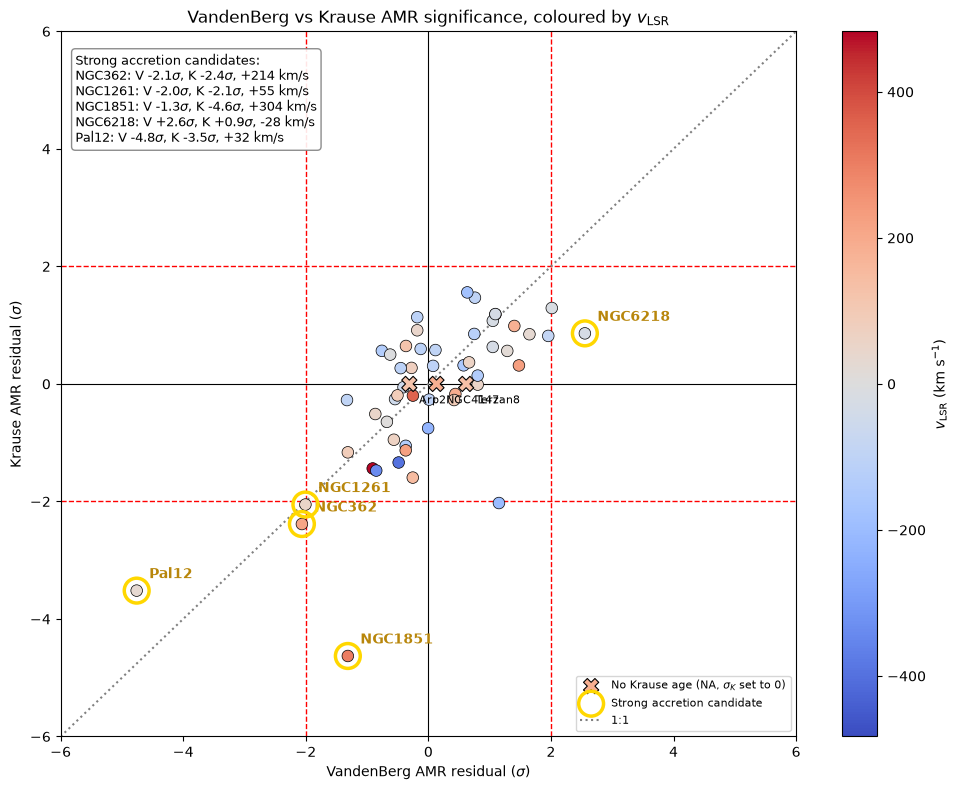

In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read in the cleaned globular cluster data
data = pd.read_csv("globular_clusters_cleaned.csv")

def fit_amr(x, y, yerr=None, clip=3, niter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if yerr is None else 1 / np.asarray(yerr)
    keep = np.ones_like(x, dtype=bool)
    for _ in range(niter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

aV, bV, sigmaV, residV = fit_amr(data["FeH"], data["Age"], data["Age_err"])
data["residV"] = residV

krause = data.dropna(subset=["Age_Krause", "FeH_Krause"]).copy()
aK, bK, sigmaK, residK = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause["residK"] = residK

# Find a column in a DataFrame by name, ignoring case and non-alphanumeric characters
def find_col(df, target):
    norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    for c in df.columns:
        if norm(c) == norm(target):
            return c
    raise KeyError(f"{target} not found in {list(df.columns)}")

id_d, id_k = find_col(data, "ClusterID"), find_col(krause, "ClusterID")
vlsr_col   = find_col(data, "vLSR")

# Create DataFrames with the relevant columns and calculate sigma values
dfV = data[[id_d, vlsr_col, "residV"]].copy()
dfV["sigV"] = dfV["residV"] / sigmaV
dfV = dfV.rename(columns={id_d: "Cluster"})

dfK = krause[[id_k, "residK"]].copy()
dfK["sigK"] = dfK["residK"] / sigmaK
dfK = dfK.rename(columns={id_k: "Cluster"})

# Merge the two DataFrames on the "Cluster" column, filling missing values in "sigK" with 0.0 and creating a boolean column "na" to indicate missing Krause ages.
m = dfV.merge(dfK, on="Cluster", how="left")
m["na"] = m["sigK"].isna()
m["sigK"] = m["sigK"].fillna(0.0)

# Define a list of strong accretion candidates and create a boolean column "strong" in the merged DataFrame to indicate whether each cluster is in that list.
strong = ["NGC362", "NGC1261", "NGC1851", "NGC6218", "Pal12"]
m["strong"] = m["Cluster"].isin(strong)

# Create a scatter plot of the VandenBerg vs Krause AMR significance, coloured by v_LSR, with special markers for clusters with missing Krause ages and strong accretion candidates.
lim = np.ceil(m[["sigV", "sigK"]].abs().values.max() + 0.5)
vmax = m[vlsr_col].abs().max()
kw = dict(cmap="coolwarm", vmin=-vmax, vmax=vmax, zorder=3)

fig, ax = plt.subplots(figsize=(10, 8))

# Normal clusters (circles) coloured by v_LSR
ok = m[~m["na"]]
sc = ax.scatter(ok["sigV"], ok["sigK"], c=ok[vlsr_col], s=70,
                edgecolors="k", linewidths=0.5, **kw)

# Clusters with missing Krause ages (X markers) coloured by v_LSR
na = m[m["na"]]
ax.scatter(na["sigV"], na["sigK"], c=na[vlsr_col], marker="X", s=120,
           edgecolors="k", linewidths=0.8, label=r"No Krause age (NA, $\sigma_K$ set to 0)", **kw)
for _, r in na.iterrows():
    ax.annotate(r["Cluster"], (r["sigV"], r["sigK"]), xytext=(7, -14),
                textcoords="offset points", fontsize=8)

fig.colorbar(sc, ax=ax, label=r"$v_{\rm LSR}$ (km s$^{-1}$)")

# Highlight strong accretion candidates (gold circles) and annotate them with their cluster names.
st = m[m["strong"]]
ax.scatter(st["sigV"], st["sigK"], s=320, facecolors="none", edgecolors="gold",
           linewidths=2.5, label="Strong accretion candidate", zorder=4)
for _, r in st.iterrows():
    ax.annotate(r["Cluster"], (r["sigV"], r["sigK"]), xytext=(9, 9),
                textcoords="offset points", fontsize=10, weight="bold", color="darkgoldenrod")

# Add horizontal and vertical lines at 0, and dashed red lines at ±2σ, along with a grey dotted line representing the 1:1 relationship.
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
for t in (-2, 2):
    ax.axhline(t, color="r", ls="--", lw=1); ax.axvline(t, color="r", ls="--", lw=1)
ax.plot([-lim, lim], [-lim, lim], color="grey", ls=":", label="1:1")

# Annotate the strong accretion candidates in the top-left corner of the plot with their VandenBerg and Krause significance values and v_LSR.
lines = ["Strong accretion candidates:"] + [
    f"{r['Cluster']}: V {r['sigV']:+.1f}$\\sigma$, K {r['sigK']:+.1f}$\\sigma$, "
    f"{r[vlsr_col]:+.0f} km/s" for _, r in st.iterrows()]
ax.text(0.02, 0.97, "\n".join(lines), transform=ax.transAxes, ha="left", va="top",
        fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))

ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(r"VandenBerg AMR residual ($\sigma$)")
ax.set_ylabel(r"Krause AMR residual ($\sigma$)")
ax.set_title(r"VandenBerg vs Krause AMR significance, coloured by $v_{\rm LSR}$")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("amr_vdb_vs_krause_vlsr_candidates.png", dpi=200)
plt.show()